# U-Net and Attention U-Net — Oxford-IIIT Pet
Google Colab practical. Binary segmentation: trimap values 1 and 3 → pet foreground (1); value 2 → background (0).

## 1. GPU
In Colab choose Runtime → Change runtime type → T4 GPU (if available).

In [1]:
import numpy as np, matplotlib.pyplot as plt, tensorflow as tf, tensorflow_datasets as tfds
SEED=42
tf.random.set_seed(SEED); np.random.seed(SEED)
print(tf.__version__, tf.config.list_physical_devices('GPU'))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download dataset
TensorFlow Datasets downloads the images and pixel masks automatically.

In [3]:
!pip install -q importlib_resources

(raw_train, raw_val, raw_test), info = tfds.load(
    'oxford_iiit_pet:4.*.*',
    split=['train[:80%]', 'train[80%:]', 'test'],
    with_info=True
)
print(info)
print('Train:', tf.data.experimental.cardinality(raw_train).numpy())
print('Validation:', tf.data.experimental.cardinality(raw_val).numpy())
print('Test:', tf.data.experimental.cardinality(raw_test).numpy())

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.1AGRJL_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.1AGRJL_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='oxford_iiit_pet',
    full_name='oxford_iiit_pet/4.0.0',
    description="""
    The Oxford-IIIT pet dataset is a 37 category pet image dataset with roughly 200
    images for each class. The images have large variations in scale, pose and
    lighting. All images have an associated ground truth annotation of breed and
    species. Additionally, head bounding boxes are provided for the training split,
    allowing using this dataset for simple object detection tasks. In the test
    split, the bounding boxes are empty.
    """,
    homepage='http://www.robots.ox.ac.uk/~vgg/data/pets/',
    data_dir='/root/tensorflow_datasets/oxford_iiit_pet/4.0.0',
    file_format=tfrecord,
    download_size=773.52 MiB,
    dataset_size=773.68 MiB,
    features=FeaturesDict({
        'file_name': Text(shape=(), dtype=string),
       

## 3. Preprocess data
Images are resized with bilinear interpolation; masks use nearest-neighbor interpolation to preserve labels. Pet and boundary pixels are foreground.

In [4]:
SIZE=128
BATCH=16
AUTOTUNE=tf.data.AUTOTUNE

def preprocess(ex):
    image=tf.image.resize(ex['image'], (SIZE,SIZE), method='bilinear')
    image=tf.cast(image,tf.float32)/255.0
    mask=tf.image.resize(ex['segmentation_mask'],(SIZE,SIZE),method='nearest')
    mask=tf.cast(tf.logical_or(mask==1,mask==3),tf.float32)
    return image,mask

def augment(image,mask):
    flip=tf.random.uniform(())>0.5
    image=tf.cond(flip,lambda:tf.image.flip_left_right(image),lambda:image)
    mask=tf.cond(flip,lambda:tf.image.flip_left_right(mask),lambda:mask)
    return image,mask

def pipeline(ds,training=False):
    ds=ds.map(preprocess,num_parallel_calls=AUTOTUNE)
    if training:
        ds=ds.shuffle(1000,seed=SEED).map(augment,num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds=pipeline(raw_train,True)
val_ds=pipeline(raw_val)
test_ds=pipeline(raw_test)
print('Datasets ready')

Datasets ready


## 4. View sample images and masks

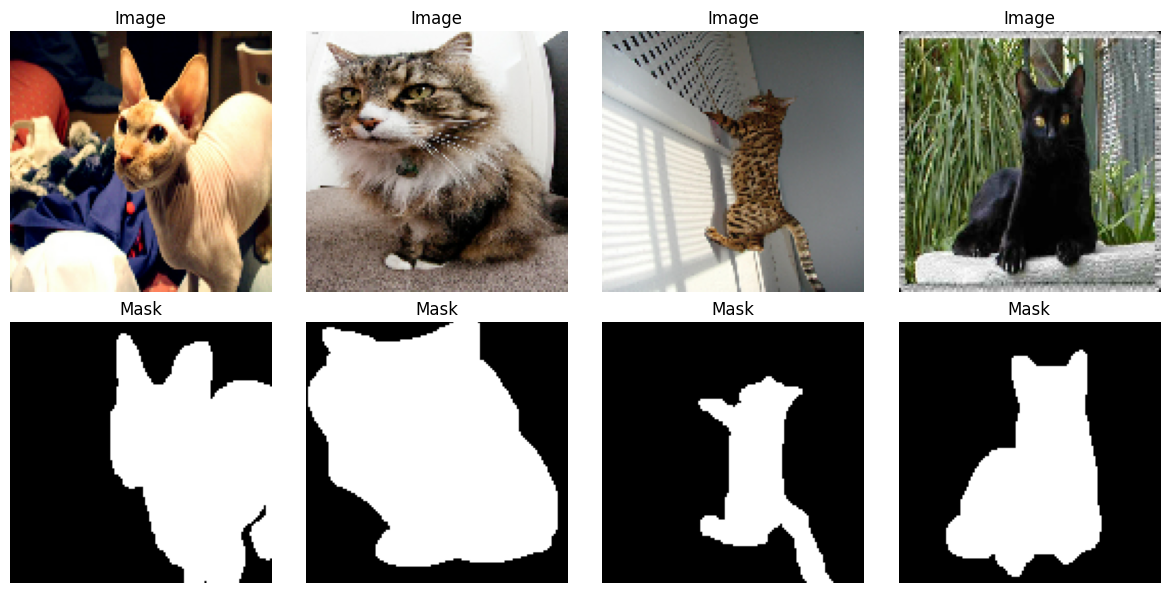

In [5]:
images,masks=next(iter(train_ds))
plt.figure(figsize=(12,6))
for i in range(4):
    plt.subplot(2,4,i+1); plt.imshow(images[i]); plt.title('Image'); plt.axis('off')
    plt.subplot(2,4,i+5); plt.imshow(tf.squeeze(masks[i]),cmap='gray',vmin=0,vmax=1); plt.title('Mask'); plt.axis('off')
plt.tight_layout(); plt.show()

## 5. Loss and IoU

In [6]:
def dice_loss(y_true,y_pred,smooth=1e-6):
    axes=[1,2,3]
    inter=tf.reduce_sum(y_true*y_pred,axis=axes)
    denom=tf.reduce_sum(y_true+y_pred,axis=axes)
    return 1-tf.reduce_mean((2*inter+smooth)/(denom+smooth))

def combined_loss(y_true,y_pred):
    bce=tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true,y_pred))
    return bce+dice_loss(y_true,y_pred)

@tf.keras.utils.register_keras_serializable()
def binary_iou(y_true,y_pred):
    yt=tf.cast(y_true>0.5,tf.float32)
    yp=tf.cast(y_pred>0.5,tf.float32)
    inter=tf.reduce_sum(yt*yp,axis=[1,2,3])
    union=tf.reduce_sum(tf.cast((yt+yp)>0,tf.float32),axis=[1,2,3])
    return tf.reduce_mean((inter+1e-6)/(union+1e-6))

## 6. U-Net building blocks and classic U-Net

In [7]:
def conv_block(x,f,name):
    x=tf.keras.layers.Conv2D(f,3,padding='same',kernel_initializer='he_normal',name=name+'_c1')(x)
    x=tf.keras.layers.BatchNormalization()(x); x=tf.keras.layers.Activation('relu')(x)
    x=tf.keras.layers.Conv2D(f,3,padding='same',kernel_initializer='he_normal',name=name+'_c2')(x)
    x=tf.keras.layers.BatchNormalization()(x); x=tf.keras.layers.Activation('relu')(x)
    return x

def upsample(x):
    return tf.keras.layers.UpSampling2D(interpolation='bilinear')(x)

def build_unet():
    inp=tf.keras.Input((SIZE,SIZE,3))
    c1=conv_block(inp,32,'enc1'); p1=tf.keras.layers.MaxPooling2D()(c1)
    c2=conv_block(p1,64,'enc2'); p2=tf.keras.layers.MaxPooling2D()(c2)
    c3=conv_block(p2,128,'enc3'); p3=tf.keras.layers.MaxPooling2D()(c3)
    c4=conv_block(p3,256,'enc4'); p4=tf.keras.layers.MaxPooling2D()(c4)
    b=conv_block(p4,512,'bottleneck')
    u4=upsample(b); d4=conv_block(tf.keras.layers.Concatenate()([u4,c4]),256,'dec4')
    u3=upsample(d4); d3=conv_block(tf.keras.layers.Concatenate()([u3,c3]),128,'dec3')
    u2=upsample(d3); d2=conv_block(tf.keras.layers.Concatenate()([u2,c2]),64,'dec2')
    u1=upsample(d2); d1=conv_block(tf.keras.layers.Concatenate()([u1,c1]),32,'dec1')
    out=tf.keras.layers.Conv2D(1,1,activation='sigmoid')(d1)
    return tf.keras.Model(inp,out,name='UNet')

unet=build_unet()
unet.summary()

Model: "UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_c1 (Conv2D)    │ (None, 128, 128,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ enc1_c1[0][0]     │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_c2 (Conv2D)    │ (None, 128, 128,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ enc1_c2[0][0]     │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_c1 (Conv2D)    │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ enc2_c1[0][0]     │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_c2 (Conv2D)    │ (None, 64, 64,    │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ enc2_c2[0][0]     │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc3_c1 (Conv2D)    │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ enc3_c1[0][0]   

 Total params: 7,858,433 (29.98 MB)

 Trainable params: 7,852,545 (29.96 MB)

 Non-trainable params: 5,888 (23.00 KB)

## 7. Attention Gate and Attention U-Net

In [8]:
def attention_gate(skip,gate,inter,name):
    theta=tf.keras.layers.Conv2D(inter,1,padding='same',name=name+'_theta')(skip)
    phi=tf.keras.layers.Conv2D(inter,1,padding='same',name=name+'_phi')(gate)
    x=tf.keras.layers.Activation('relu')(tf.keras.layers.Add()([theta,phi]))
    alpha=tf.keras.layers.Activation('sigmoid')(
        tf.keras.layers.Conv2D(1,1,padding='same',name=name+'_psi')(x))
    return tf.keras.layers.Multiply()([skip,alpha])

def build_attention_unet():
    inp=tf.keras.Input((SIZE,SIZE,3))
    c1=conv_block(inp,32,'a_enc1'); p1=tf.keras.layers.MaxPooling2D()(c1)
    c2=conv_block(p1,64,'a_enc2'); p2=tf.keras.layers.MaxPooling2D()(c2)
    c3=conv_block(p2,128,'a_enc3'); p3=tf.keras.layers.MaxPooling2D()(c3)
    c4=conv_block(p3,256,'a_enc4'); p4=tf.keras.layers.MaxPooling2D()(c4)
    b=conv_block(p4,512,'a_bottleneck')
    u4=upsample(b); s4=attention_gate(c4,u4,128,'gate4')
    d4=conv_block(tf.keras.layers.Concatenate()([u4,s4]),256,'a_dec4')
    u3=upsample(d4); s3=attention_gate(c3,u3,64,'gate3')
    d3=conv_block(tf.keras.layers.Concatenate()([u3,s3]),128,'a_dec3')
    u2=upsample(d3); s2=attention_gate(c2,u2,32,'gate2')
    d2=conv_block(tf.keras.layers.Concatenate()([u2,s2]),64,'a_dec2')
    u1=upsample(d2); s1=attention_gate(c1,u1,16,'gate1')
    d1=conv_block(tf.keras.layers.Concatenate()([u1,s1]),32,'a_dec1')
    out=tf.keras.layers.Conv2D(1,1,activation='sigmoid')(d1)
    return tf.keras.Model(inp,out,name='Attention_UNet')

attention_unet=build_attention_unet()
attention_unet.summary()

Model: "Attention_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ a_enc1_c1 (Conv2D)  │ (None, 128, 128,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ a_enc1_c1[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_18       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ a_enc1_c2 (Conv2D)  │ (None, 128, 128,  │      9,248 │ activation_18[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ a_enc1_c2[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_19       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 64, 64,    │          0 │ activation_19[0]… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ a_enc2_c1 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ a_enc2_c1[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_20       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ a_enc2_c2 (Conv2D)  │ (None, 64, 64,    │     36,928 │ activation_20[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ a_enc2_c2[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_21       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 32, 32,    │          0 │ activation_21[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ a_enc3_c1 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_5[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ a_enc3_c1[0][0] 

 Total params: 7,989,717 (30.48 MB)

 Trainable params: 7,983,829 (30.46 MB)

 Non-trainable params: 5,888 (23.00 KB)

## 8. Compile and train U-Net
Both models use the same data, loss, optimizer, epoch budget and callbacks for a fair comparison.

In [9]:
def compile_model(model):
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
                  loss=combined_loss,metrics=[binary_iou])

def train_model(model,name,epochs=20):
    compile_model(model)
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_binary_iou',mode='max',
                                         patience=5,restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=0.5,
                                             patience=2,min_lr=1e-6),
        tf.keras.callbacks.ModelCheckpoint('/content/'+name+'_best.keras',
                                           monitor='val_binary_iou',mode='max',
                                           save_best_only=True)
    ]
    return model.fit(train_ds,validation_data=val_ds,epochs=epochs,callbacks=callbacks)

history_unet=train_model(unet,'unet',epochs=20)

Epoch 1/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 81s 138ms/step - binary_iou: 0.6128 - loss: 0.7796 - val_binary_iou: 0.6082 - val_loss: 0.7912 - learning_rate: 1.0000e-04
Epoch 2/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 27s 129ms/step - binary_iou: 0.6986 - loss: 0.5958 - val_binary_iou: 0.7036 - val_loss: 0.5882 - learning_rate: 1.0000e-04
Epoch 3/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 27s 134ms/step - binary_iou: 0.7311 - loss: 0.5255 - val_binary_iou: 0.7325 - val_loss: 0.5121 - learning_rate: 1.0000e-04
Epoch 4/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 26s 131ms/step - binary_iou: 0.7529 - loss: 0.4796 - val_binary_iou: 0.7565 - val_loss: 0.4677 - learning_rate: 1.0000e-04
Epoch 5/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 26s 131ms/step - binary_iou: 0.7713 - loss: 0.4409 - val_binary_iou: 0.7593 - val_loss: 0.4589 - learning_rate: 1.0000e-04
Epoch 6/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 26s 128ms/step - binary_iou: 0.7874 - loss: 0.4070 - val_binary_iou: 0.7607 - val_loss: 0.4523 - learning_rate: 1.0000e-04
Epoch 7/20
184/184 ━━━

## 9. Train Attention U-Net

In [10]:
history_attention=train_model(attention_unet,'attention_unet',epochs=20)

Epoch 1/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 73s 169ms/step - binary_iou: 0.5951 - loss: 0.8011 - val_binary_iou: 0.6153 - val_loss: 0.7733 - learning_rate: 1.0000e-04
Epoch 2/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 28s 141ms/step - binary_iou: 0.6799 - loss: 0.6245 - val_binary_iou: 0.6808 - val_loss: 0.6504 - learning_rate: 1.0000e-04
Epoch 3/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 28s 139ms/step - binary_iou: 0.7211 - loss: 0.5420 - val_binary_iou: 0.7102 - val_loss: 0.5846 - learning_rate: 1.0000e-04
Epoch 4/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 28s 140ms/step - binary_iou: 0.7447 - loss: 0.4911 - val_binary_iou: 0.7232 - val_loss: 0.5551 - learning_rate: 1.0000e-04
Epoch 5/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 28s 141ms/step - binary_iou: 0.7619 - loss: 0.4554 - val_binary_iou: 0.7476 - val_loss: 0.4871 - learning_rate: 1.0000e-04
Epoch 6/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 29s 140ms/step - binary_iou: 0.7770 - loss: 0.4250 - val_binary_iou: 0.7438 - val_loss: 0.4974 - learning_rate: 1.0000e-04
Epoch 7/20
184/184 ━━━

## 10. Plot training curves

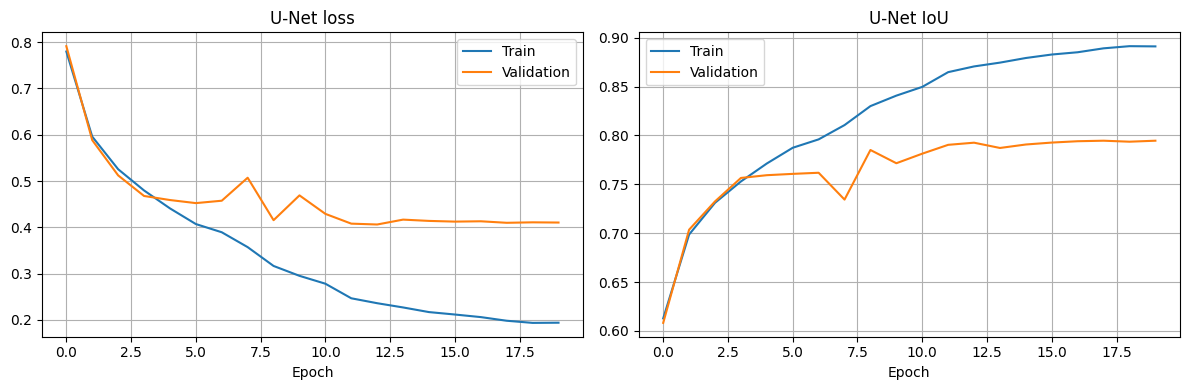

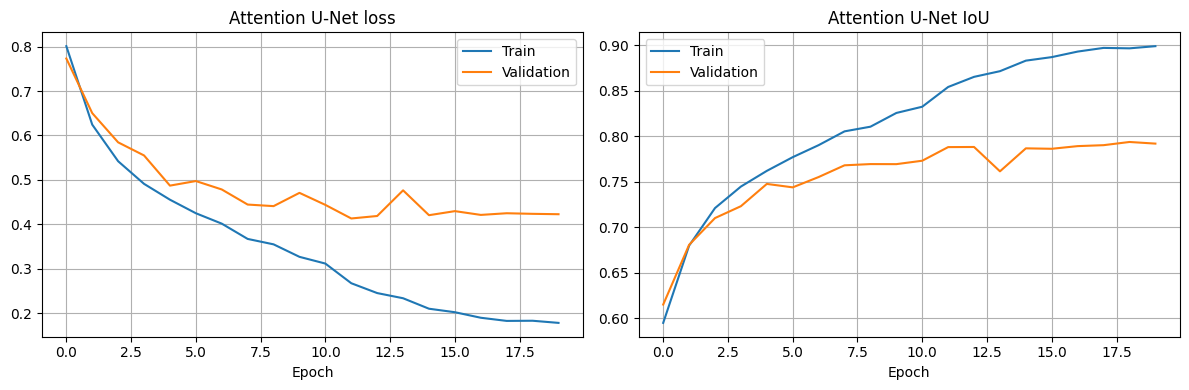

In [11]:
def plot_history(h,title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(h.history['loss'],label='Train'); plt.plot(h.history['val_loss'],label='Validation')
    plt.title(title+' loss'); plt.xlabel('Epoch'); plt.legend(); plt.grid()
    plt.subplot(1,2,2)
    plt.plot(h.history['binary_iou'],label='Train'); plt.plot(h.history['val_binary_iou'],label='Validation')
    plt.title(title+' IoU'); plt.xlabel('Epoch'); plt.legend(); plt.grid()
    plt.tight_layout(); plt.show()

plot_history(history_unet,'U-Net')
plot_history(history_attention,'Attention U-Net')

## 11. Evaluate on the held-out test set

In [12]:
res_unet=unet.evaluate(test_ds,return_dict=True,verbose=1)
res_att=attention_unet.evaluate(test_ds,return_dict=True,verbose=1)
print('U-Net test IoU:',round(res_unet['binary_iou'],4))
print('Attention U-Net test IoU:',round(res_att['binary_iou'],4))

230/230 ━━━━━━━━━━━━━━━━━━━━ 20s 85ms/step - binary_iou: 0.7983 - loss: 0.4047
230/230 ━━━━━━━━━━━━━━━━━━━━ 17s 72ms/step - binary_iou: 0.8021 - loss: 0.4032
U-Net test IoU: 0.7983
Attention U-Net test IoU: 0.8021


## 12. Visualize predictions

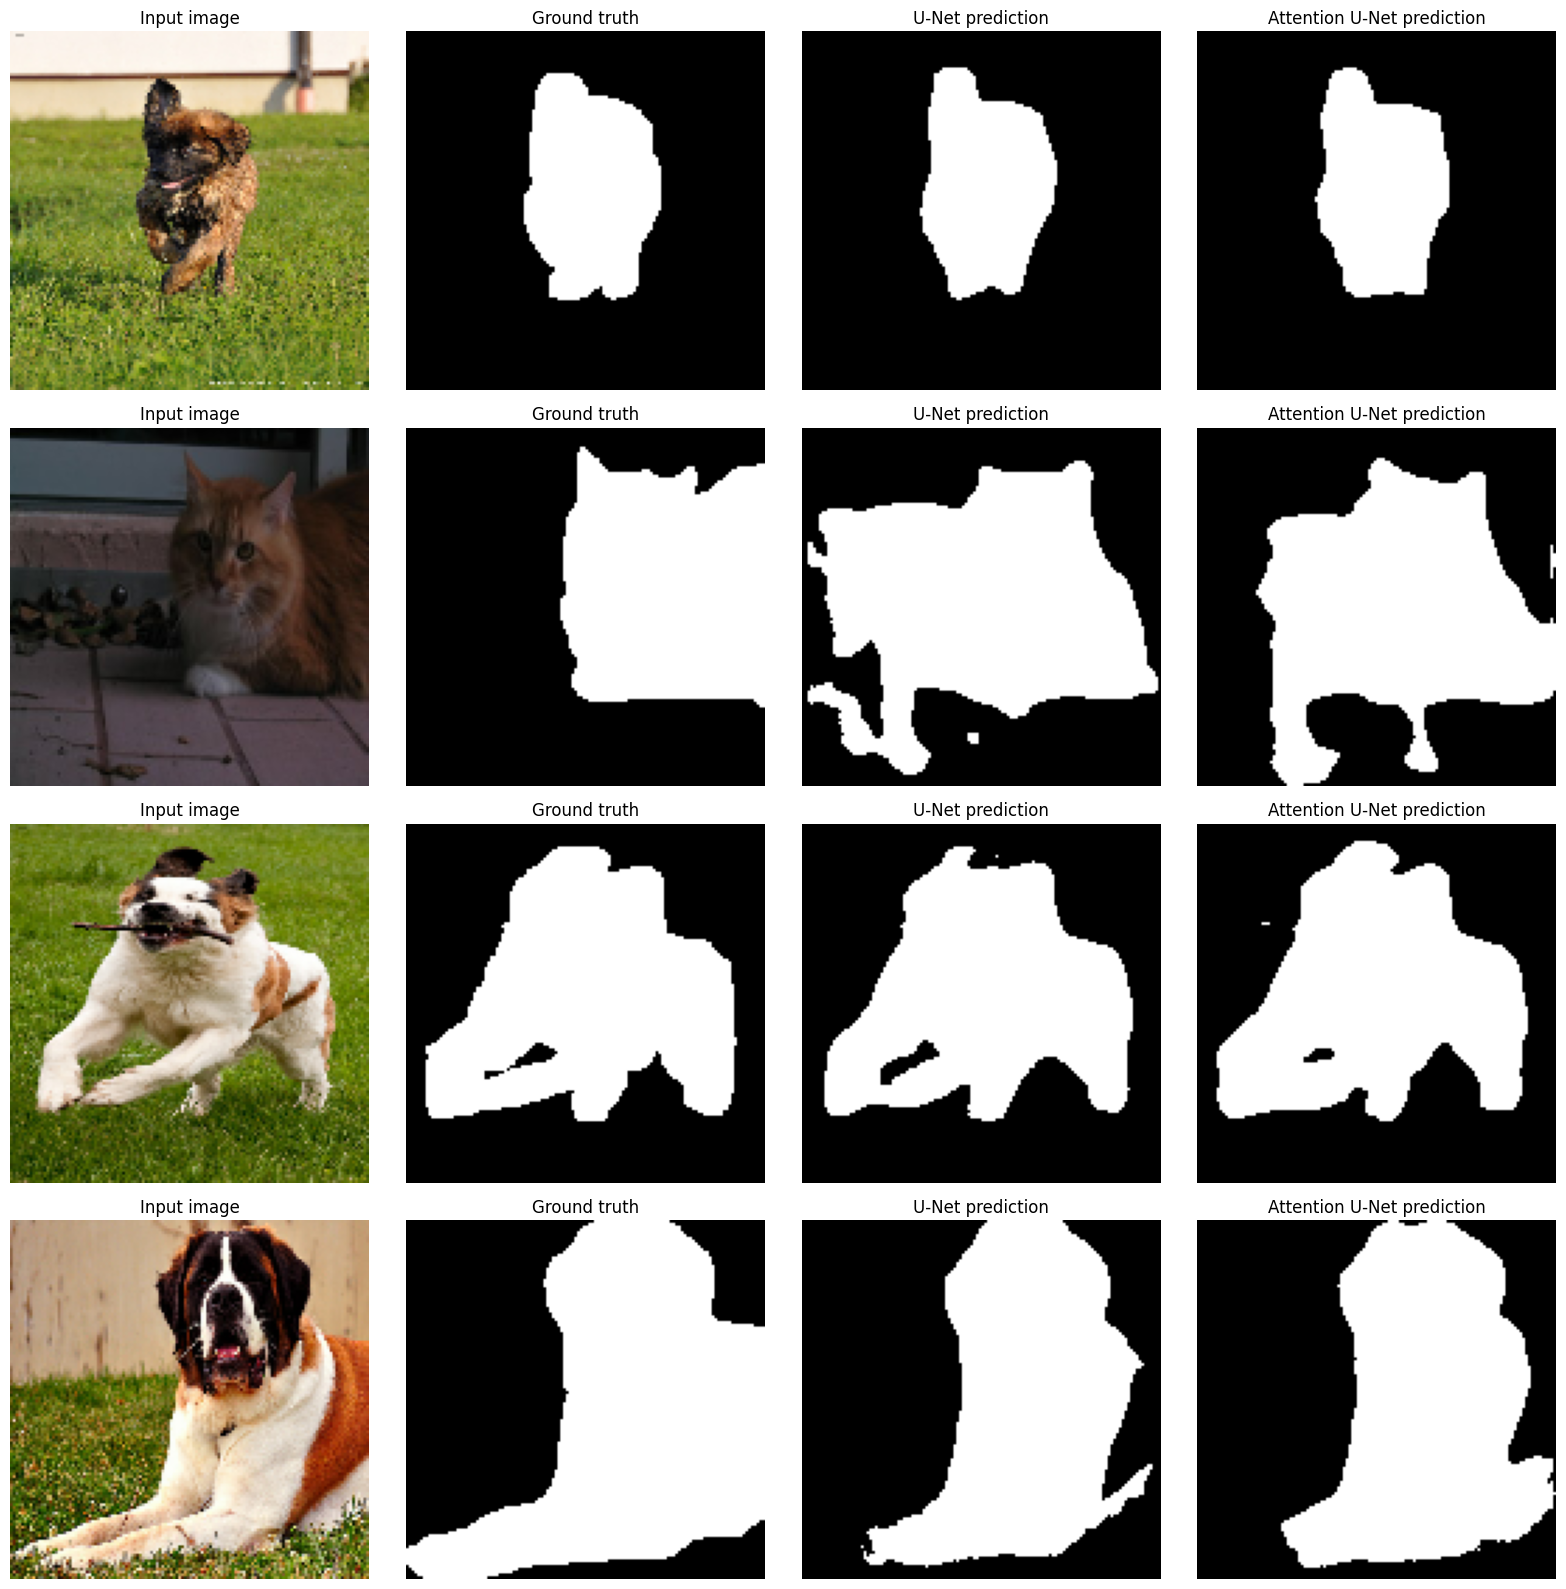

In [13]:
for imgs,true_masks in test_ds.take(1):
    p1=unet.predict(imgs,verbose=0)
    p2=attention_unet.predict(imgs,verbose=0)
    n=min(4,len(imgs))
    plt.figure(figsize=(16,4*n))
    for i in range(n):
        for j,(arr,title,cmap) in enumerate([
            (imgs[i],'Input image',None),
            (tf.squeeze(true_masks[i]),'Ground truth','gray'),
            (p1[i,...,0]>=0.5,'U-Net prediction','gray'),
            (p2[i,...,0]>=0.5,'Attention U-Net prediction','gray')]):
            plt.subplot(n,4,4*i+j+1)
            plt.imshow(arr,cmap=cmap); plt.title(title); plt.axis('off')
    plt.tight_layout(); plt.show()

## 13. Compare IoU scores

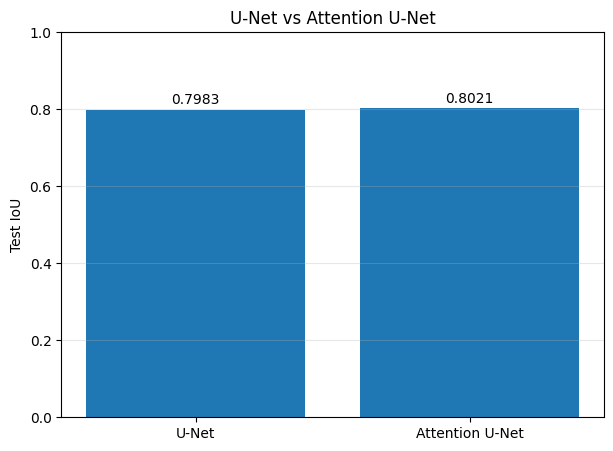

In [14]:
names=['U-Net','Attention U-Net']
scores=[res_unet['binary_iou'],res_att['binary_iou']]
plt.figure(figsize=(7,5))
bars=plt.bar(names,scores)
plt.ylim(0,1); plt.ylabel('Test IoU'); plt.title('U-Net vs Attention U-Net')
plt.grid(axis='y',alpha=0.3)
for bar,v in zip(bars,scores):
    plt.text(bar.get_x()+bar.get_width()/2,v+0.015,f'{v:.4f}',ha='center')
plt.show()

## 14. Save trained models

In [15]:
unet.save('/content/unet_oxford_pet.keras')
attention_unet.save('/content/attention_unet_oxford_pet.keras')
print('Saved both models in /content/')

Saved both models in /content/


## Conclusion and interpretation

U-Net uses encoder-decoder processing with direct skip connections. Attention U-Net adds learned attention gates to weight encoder features before they are passed to the decoder. Compare both models using their **held-out test IoU**; do not assume Attention U-Net must always perform better.

\[
IoU=\frac{TP}{TP+FP+FN}
\]

A higher IoU means greater overlap between the predicted pet mask and the ground-truth mask.

**Dataset:** Oxford-IIIT Pet, Parkhi et al., CVPR 2012. Dataset documentation: https://www.tensorflow.org/datasets/catalog/oxford_iiit_pet
